# PTB-XL Label Creation and Data Splitting

This notebook prepares the PTB-XL dataset for myocardial infarction detection.

## Objectives

- Load PTB-XL metadata
- Load SCP diagnostic definitions
- Parse ECG diagnostic codes
- Identify myocardial infarction (MI) records
- Create binary labels:
    - 0 = Non-MI
    - 1 = MI
- Use the official PTB-XL stratification folds
- Train: folds 1–8
- Validation: fold 9
- Test: fold 10
- Verify patient-level leakage
- Save train.csv, val.csv and test.csv

In [1]:
from pathlib import Path
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path("..").resolve()

PTBXL_ROOT = PROJECT_ROOT / "PTB_XL"

DATABASE_CSV = PTBXL_ROOT / "ptbxl_database.csv"
SCP_CSV = PTBXL_ROOT / "scp_statements.csv"

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:")
print(PROJECT_ROOT)

print("\nPTB-XL root:")
print(PTBXL_ROOT)

print("\nDatabase:")
print(DATABASE_CSV)

print("\nSCP statements:")
print(SCP_CSV)

print("\nSplit directory:")
print(SPLIT_DIR)

Project root:
E:\Academia\archive\ECG_MI_Project

PTB-XL root:
E:\Academia\archive\ECG_MI_Project\PTB_XL

Database:
E:\Academia\archive\ECG_MI_Project\PTB_XL\ptbxl_database.csv

SCP statements:
E:\Academia\archive\ECG_MI_Project\PTB_XL\scp_statements.csv

Split directory:
E:\Academia\archive\ECG_MI_Project\data\splits


In [3]:
print("PTB-XL folder exists:", PTBXL_ROOT.exists())
print("ptbxl_database.csv exists:", DATABASE_CSV.exists())
print("scp_statements.csv exists:", SCP_CSV.exists())

PTB-XL folder exists: True
ptbxl_database.csv exists: True
scp_statements.csv exists: True


In [4]:
df = pd.read_csv(
    DATABASE_CSV,
    index_col="ecg_id"
)

scp_df = pd.read_csv(
    SCP_CSV,
    index_col=0
)

print("ECG records:", len(df))
print("SCP statements:", len(scp_df))

ECG records: 21799
SCP statements: 71


In [5]:
print(df.columns.tolist())

['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


In [6]:
df.head()

,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [7]:
print(scp_df.columns.tolist())

['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class', 'diagnostic_subclass', 'Statement Category', 'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code', 'DICOM Code']


In [41]:
scp_df.head(10)

,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7
IMI,inferior myocardial infarction,1.0,NaN,NaN,MI,IMI,Myocardial Infarction,inferior myocardial infarction,161.0,NaN,NaN,NaN
ASMI,anteroseptal myocardial infarction,1.0,NaN,NaN,MI,AMI,Myocardial Infarction,anteroseptal myocardial infarction,165.0,NaN,NaN,NaN
LVH,left ventricular hypertrophy,1.0,NaN,NaN,HYP,LVH,Ventricular Hypertrophy,left ventricular hypertrophy,142.0,NaN,C71076,NaN
LAFB,left anterior fascicular block,1.0,NaN,NaN,CD,LAFB/LPFB,Intraventricular and intra-atrial Conduction d...,left anterior fascicular block,101.0,MDC_ECG_BEAT_BLK_ANT_L_HEMI,C62267,D3-33140
ISC_,non-specific ischemic,1.0,NaN,NaN,STTC,ISC_,Basic roots for coding ST-T changes and abnorm...,ischemic ST-T changes,226.0,NaN,NaN,NaN


In [42]:
diagnostic_rows = scp_df[
    scp_df["diagnostic"] == 1
]

print(
    diagnostic_rows[
        "diagnostic_class"
    ]
    .value_counts(dropna=False)
)

diagnostic_class
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


In [9]:
mi_statements = scp_df[
    (scp_df["diagnostic"] == 1) &
    (scp_df["diagnostic_class"] == "MI")
]

print("Number of MI-related SCP statements:", len(mi_statements))

mi_statements[
    [
        "diagnostic_class",
        "diagnostic_subclass"
    ]
]

Number of MI-related SCP statements: 14


,diagnostic_class,diagnostic_subclass
IMI,MI,IMI
ASMI,MI,AMI
ILMI,MI,IMI
AMI,MI,AMI
ALMI,MI,AMI
INJAS,MI,AMI
LMI,MI,LMI
INJAL,MI,AMI
IPLMI,MI,IMI
IPMI,MI,IMI


In [10]:
MI_CODES = set(
    mi_statements.index
)

print("MI SCP codes:")

for code in sorted(MI_CODES):
    print(code)

MI SCP codes:
ALMI
AMI
ASMI
ILMI
IMI
INJAL
INJAS
INJIL
INJIN
INJLA
IPLMI
IPMI
LMI
PMI


In [11]:
df["scp_codes_parsed"] = df[
    "scp_codes"
].apply(ast.literal_eval)

In [12]:
print(
    df.iloc[0]["scp_codes_parsed"]
)

print(
    type(
        df.iloc[0]["scp_codes_parsed"]
    )
)

{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
<class 'dict'>


In [13]:
def contains_mi(scp_dict):
    codes = set(scp_dict.keys())

    return int(
        len(codes.intersection(MI_CODES)) > 0
    )

In [14]:
df["label"] = df[
    "scp_codes_parsed"
].apply(contains_mi)

df["class_name"] = df[
    "label"
].map({
    0: "Non_MI",
    1: "MI"
})

In [15]:
print(
    df["class_name"]
    .value_counts()
)

print("\nPercentages:")

print(
    df["class_name"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class_name
Non_MI    16330
MI         5469
Name: count, dtype: int64

Percentages:
class_name
Non_MI    74.91
MI        25.09
Name: proportion, dtype: float64


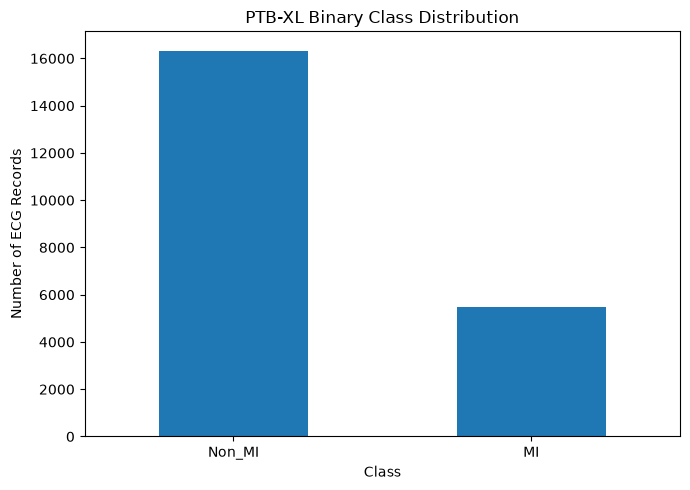

In [16]:
counts = df[
    "class_name"
].value_counts()

plt.figure(
    figsize=(7, 5)
)

counts.plot(
    kind="bar"
)

plt.title(
    "PTB-XL Binary Class Distribution"
)

plt.xlabel(
    "Class"
)

plt.ylabel(
    "Number of ECG Records"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

In [17]:
mi_samples = df[
    df["label"] == 1
][
    [
        "patient_id",
        "scp_codes",
        "strat_fold",
        "filename_lr"
    ]
]

mi_samples.head(10)

,patient_id,scp_codes,strat_fold,filename_lr
ecg_id,,,,
8,11275.0,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",9,records100/00000/00008_lr
39,13619.0,"{'IMI': 15.0, 'LNGQT': 100.0, 'NST_': 100.0, '...",9,records100/00000/00039_lr
50,16961.0,"{'LMI': 15.0, 'IVCD': 100.0, 'SR': 0.0}",7,records100/00000/00050_lr
63,15265.0,"{'ASMI': 15.0, 'ABQRS': 0.0, 'SR': 0.0}",10,records100/00000/00063_lr
77,8555.0,"{'AMI': 50.0, 'IRBBB': 100.0, 'SR': 0.0}",6,records100/00000/00077_lr
103,13722.0,"{'IMI': 15.0, 'LAFB': 100.0, 'ABQRS': 0.0, 'ST...",4,records100/00000/00103_lr
106,16066.0,"{'ASMI': 50.0, 'LVH': 15.0, 'ABQRS': 0.0, 'SR'...",5,records100/00000/00106_lr
131,13698.0,"{'ASMI': 50.0, 'ABQRS': 0.0, 'SR': 0.0}",8,records100/00000/00131_lr
146,13447.0,"{'IMI': 35.0, 'ISCLA': 100.0, 'SEHYP': 50.0, '...",7,records100/00000/00146_lr


In [18]:
non_mi_samples = df[
    df["label"] == 0
][
    [
        "patient_id",
        "scp_codes",
        "strat_fold",
        "filename_lr"
    ]
]

non_mi_samples.head(10)

,patient_id,scp_codes,strat_fold,filename_lr
ecg_id,,,,
1,15709.0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",3,records100/00000/00001_lr
2,13243.0,"{'NORM': 80.0, 'SBRAD': 0.0}",2,records100/00000/00002_lr
3,20372.0,"{'NORM': 100.0, 'SR': 0.0}",5,records100/00000/00003_lr
4,17014.0,"{'NORM': 100.0, 'SR': 0.0}",3,records100/00000/00004_lr
5,17448.0,"{'NORM': 100.0, 'SR': 0.0}",4,records100/00000/00005_lr
6,19005.0,"{'NORM': 100.0, 'SR': 0.0}",4,records100/00000/00006_lr
7,16193.0,"{'NORM': 100.0, 'SR': 0.0}",7,records100/00000/00007_lr
9,18792.0,"{'NORM': 100.0, 'SR': 0.0}",10,records100/00000/00009_lr
10,9456.0,"{'NORM': 100.0, 'SR': 0.0}",9,records100/00000/00010_lr


In [19]:
print(
    df["strat_fold"]
    .value_counts()
    .sort_index()
)

strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64


In [20]:
patient_fold_counts = (
    df.groupby("patient_id")[
        "strat_fold"
    ]
    .nunique()
)

multi_fold_patients = patient_fold_counts[
    patient_fold_counts > 1
]

print(
    "Patients appearing in multiple folds:",
    len(multi_fold_patients)
)

Patients appearing in multiple folds: 0


In [21]:
train_df = df[
    df["strat_fold"].between(1, 8)
].copy()

val_df = df[
    df["strat_fold"] == 9
].copy()

test_df = df[
    df["strat_fold"] == 10
].copy()

In [22]:
print(
    "Train:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)

print(
    "Total:",
    len(train_df)
    + len(val_df)
    + len(test_df)
)

Train: 17418
Validation: 2183
Test: 2198
Total: 21799


In [23]:
split_distribution = pd.DataFrame({
    "Train": train_df[
        "class_name"
    ].value_counts(),

    "Validation": val_df[
        "class_name"
    ].value_counts(),

    "Test": test_df[
        "class_name"
    ].value_counts()
})

split_distribution

,Train,Validation,Test
class_name,,,
Non_MI,13039,1643,1648
MI,4379,540,550


In [24]:
split_percentages = pd.DataFrame({
    "Train (%)":
        train_df[
            "class_name"
        ]
        .value_counts(normalize=True)
        .mul(100),

    "Validation (%)":
        val_df[
            "class_name"
        ]
        .value_counts(normalize=True)
        .mul(100),

    "Test (%)":
        test_df[
            "class_name"
        ]
        .value_counts(normalize=True)
        .mul(100)
})

split_percentages.round(2)

,Train (%),Validation (%),Test (%)
class_name,,,
Non_MI,74.86,75.26,74.98
MI,25.14,24.74,25.02


In [25]:
train_patients = set(
    train_df["patient_id"]
)

val_patients = set(
    val_df["patient_id"]
)

test_patients = set(
    test_df["patient_id"]
)


print(
    "Train-Val patient overlap:",
    len(
        train_patients
        & val_patients
    )
)

print(
    "Train-Test patient overlap:",
    len(
        train_patients
        & test_patients
    )
)

print(
    "Val-Test patient overlap:",
    len(
        val_patients
        & test_patients
    )
)

Train-Val patient overlap: 0
Train-Test patient overlap: 0
Val-Test patient overlap: 0


In [26]:
train_ids = set(
    train_df.index
)

val_ids = set(
    val_df.index
)

test_ids = set(
    test_df.index
)


print(
    "Train-Val ECG overlap:",
    len(train_ids & val_ids)
)

print(
    "Train-Test ECG overlap:",
    len(train_ids & test_ids)
)

print(
    "Val-Test ECG overlap:",
    len(val_ids & test_ids)
)

Train-Val ECG overlap: 0
Train-Test ECG overlap: 0
Val-Test ECG overlap: 0


In [27]:
train_files = set(
    train_df["filename_lr"]
)

val_files = set(
    val_df["filename_lr"]
)

test_files = set(
    test_df["filename_lr"]
)


print(
    "Train-Val filename overlap:",
    len(train_files & val_files)
)

print(
    "Train-Test filename overlap:",
    len(train_files & test_files)
)

print(
    "Val-Test filename overlap:",
    len(val_files & test_files)
)

Train-Val filename overlap: 0
Train-Test filename overlap: 0
Val-Test filename overlap: 0


In [28]:
train_df = train_df.reset_index()
val_df = val_df.reset_index()
test_df = test_df.reset_index()

In [29]:
FINAL_COLUMNS = [
    "ecg_id",
    "patient_id",
    "filename_lr",
    "filename_hr",
    "strat_fold",
    "label",
    "class_name",
    "scp_codes"
]

In [30]:
train_final = train_df[
    FINAL_COLUMNS
].copy()

val_final = val_df[
    FINAL_COLUMNS
].copy()

test_final = test_df[
    FINAL_COLUMNS
].copy()

In [31]:
train_final.head()

,ecg_id,patient_id,filename_lr,filename_hr,strat_fold,label,class_name,scp_codes
0,1,15709.0,records100/00000/00001_lr,records500/00000/00001_hr,3,0,Non_MI,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,13243.0,records100/00000/00002_lr,records500/00000/00002_hr,2,0,Non_MI,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,20372.0,records100/00000/00003_lr,records500/00000/00003_hr,5,0,Non_MI,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014.0,records100/00000/00004_lr,records500/00000/00004_hr,3,0,Non_MI,"{'NORM': 100.0, 'SR': 0.0}"
4,5,17448.0,records100/00000/00005_lr,records500/00000/00005_hr,4,0,Non_MI,"{'NORM': 100.0, 'SR': 0.0}"


In [32]:
TRAIN_OUTPUT = (
    SPLIT_DIR / "train.csv"
)

VAL_OUTPUT = (
    SPLIT_DIR / "val.csv"
)

TEST_OUTPUT = (
    SPLIT_DIR / "test.csv"
)


train_final.to_csv(
    TRAIN_OUTPUT,
    index=False
)

val_final.to_csv(
    VAL_OUTPUT,
    index=False
)

test_final.to_csv(
    TEST_OUTPUT,
    index=False
)


print("Saved:")
print(TRAIN_OUTPUT)
print(VAL_OUTPUT)
print(TEST_OUTPUT)

Saved:
E:\Academia\archive\ECG_MI_Project\data\splits\train.csv
E:\Academia\archive\ECG_MI_Project\data\splits\val.csv
E:\Academia\archive\ECG_MI_Project\data\splits\test.csv


In [33]:
train_class_counts = (
    train_final["label"]
    .value_counts()
    .sort_index()
)

print(train_class_counts)

label
0    13039
1     4379
Name: count, dtype: int64


In [34]:
total_samples = len(
    train_final
)

num_classes = 2

class_weights = (
    total_samples
    /
    (
        num_classes
        * train_class_counts
    )
)

print(class_weights)

label
0    0.667919
1    1.988810
Name: count, dtype: float64


In [35]:
class_weight_df = pd.DataFrame({
    "label": [
        0,
        1
    ],

    "class_name": [
        "Non_MI",
        "MI"
    ],

    "count": [
        train_class_counts.get(
            0,
            0
        ),
        train_class_counts.get(
            1,
            0
        )
    ],

    "weight": [
        class_weights.get(
            0,
            np.nan
        ),
        class_weights.get(
            1,
            np.nan
        )
    ]
})

class_weight_df

,label,class_name,count,weight
0,0,Non_MI,13039,0.667919
1,1,MI,4379,1.988810


In [36]:
CLASS_WEIGHT_OUTPUT = (
    SPLIT_DIR /
    "class_weights.csv"
)

class_weight_df.to_csv(
    CLASS_WEIGHT_OUTPUT,
    index=False
)

print(
    "Saved:",
    CLASS_WEIGHT_OUTPUT
)

Saved: E:\Academia\archive\ECG_MI_Project\data\splits\class_weights.csv


In [37]:
train_check = pd.read_csv(
    TRAIN_OUTPUT
)

val_check = pd.read_csv(
    VAL_OUTPUT
)

test_check = pd.read_csv(
    TEST_OUTPUT
)

print(
    len(train_check),
    len(val_check),
    len(test_check)
)

17418 2183 2198


In [38]:
final_summary = pd.DataFrame({
    "Train":
        train_final[
            "class_name"
        ].value_counts(),

    "Validation":
        val_final[
            "class_name"
        ].value_counts(),

    "Test":
        test_final[
            "class_name"
        ].value_counts()
})

final_summary.loc[
    "TOTAL"
] = final_summary.sum()

final_summary

,Train,Validation,Test
class_name,,,
Non_MI,13039,1643,1648
MI,4379,540,550
TOTAL,17418,2183,2198


In [39]:
patient_summary = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test"
    ],

    "ECG Records": [
        len(train_final),
        len(val_final),
        len(test_final)
    ],

    "Unique Patients": [
        train_final[
            "patient_id"
        ].nunique(),

        val_final[
            "patient_id"
        ].nunique(),

        test_final[
            "patient_id"
        ].nunique()
    ]
})

patient_summary

,Split,ECG Records,Unique Patients
0,Train,17418,15023
1,Validation,2183,1942
2,Test,2198,1904


In [40]:
assert (
    len(
        train_patients
        & val_patients
    )
    == 0
)

assert (
    len(
        train_patients
        & test_patients
    )
    == 0
)

assert (
    len(
        val_patients
        & test_patients
    )
    == 0
)

assert (
    len(
        train_ids
        & val_ids
    )
    == 0
)

assert (
    len(
        train_ids
        & test_ids
    )
    == 0
)

assert (
    len(
        val_ids
        & test_ids
    )
    == 0
)

print(
    "All leakage checks passed."
)

All leakage checks passed.


# PTB-XL Preparation Complete

The PTB-XL metadata has been prepared for binary myocardial infarction detection.

## Classification

- `0 = Non_MI`
- `1 = MI`

MI labels were derived using diagnostic SCP statements whose diagnostic superclass is `MI`.

## Data split

The official PTB-XL stratification folds were used:

- Folds 1–8: Training
- Fold 9: Validation
- Fold 10: Test

## Leakage protection

The following were verified:

- No patient overlap between train, validation and test
- No ECG ID overlap between splits
- No filename overlap between splits
- Previous waveform hashing found no exact duplicate ECG signals

## Generated files

- `data/splits/train.csv`
- `data/splits/val.csv`
- `data/splits/test.csv`
- `data/splits/class_weights.csv`

The next stage is loading raw PTB-XL waveform data from `records100`.